# Do full practice authority laws move nurse practitioners?

**An open question in health economics, asked of the universe of nurse practitioners, month by month.**

Twenty-seven states and DC now let nurse practitioners (NPs) evaluate, diagnose, treat and prescribe without a physician's supervision or a collaborative agreement. This is *full practice authority* (FPA). Whether it changes the supply of NPs, and through which margin, matters for access to primary care and is contested:

* Markowitz and Adams (NBER WP 26896) find with the National Sample Survey of Registered Nurses that scope-of-practice restrictions are "not strong determinants of many labor market decisions", except that hours and self-employment rise without oversight requirements.
* Dillender, Lo Sasso, Phelan and Richards (JHR 2026) find with job postings that FPA raises employer demand and NP earnings and reallocates NPs toward self-employment, but "only mildly" increases employment.
* Perry (2012) finds with 1991 to 2003 survey data that NPs are less likely to leave a state that grants more authority.
* Bae, Norris, Shakya and Timmons (SSRN 4402185, 2023) compare Maryland, which adopted FPA in October 2015, with Pennsylvania using annual NPPES counts from 2016 to 2021. Maryland's border counties have 22 more NPs per 100,000 residents. They write that NPPES data were "not available prior to 2016", that it "does not allow us to account for provider mobility", and that without pre-2016 trends "we cannot perform a difference in differences estimation".

All three limits come from using NPPES as a snapshot. This notebook uses the monthly history instead: every NP's practice state and sole-proprietor flag on every monthly file since April 2011. It (1) replicates and extends the Maryland comparison with a pre-period and with mobility, then (2) runs the staggered-adoption design across every state that adopted FPA inside the monthly window, for four outcomes: the stock of NPs, entry of new NPs, cross-state moves, and independence (sole-proprietor status).

The point of the notebook is the data, not a verdict. Read the estimates as what a researcher would get on day one, before the choices (regional controls, population weights, time-in-practice rules, anticipation) that a paper would have to make.

In [1]:
import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
from differences import ATTgt
import nppes_nb as nb

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
con = nb.connect()

## 1. When each state adopted FPA

The treatment dates are the month the statute or rule took effect, from McMichael and Markowitz (NBER WP 28192, Table 2) for 1998 to 2020, extended with the Massachusetts (January 2021), New York (April 2022, NPs with 3,600 hours) and Kansas (July 2022) laws. `notebooks/data/SOURCES.md` has the citations. The second classification is the American Association of Nurse Practitioners (AANP) map, which disagrees on Illinois, Virginia, West Virginia and Florida; we use it for a sensitivity check.

In [2]:
fpa = nb.fpa_dates()
window = fpa[(fpa.coding == "statute") & (fpa.fpa_effective >= "2011-04-01")].sort_values("fpa_effective")
print(f"{(fpa.coding == 'always').sum()} states had FPA before 1998, {(fpa.coding == 'never').sum()} never adopted it, "
      f"{(fpa.coding == 'statute').sum()} adopted by statute, of which {len(window)} inside the monthly window:")
window[["state", "fpa_effective", "partial", "aanp_full_practice", "note"]].assign(fpa_effective=lambda d: d.fpa_effective.dt.strftime("%Y-%m")).reset_index(drop=True)

9 states had FPA before 1998, 19 never adopted it, 23 adopted by statute, of which 18 inside the monthly window:


,state,fpa_effective,partial,aanp_full_practice,note
0,VT,2011-06,False,True,"Time-in-practice: 2,400 hours or 24 months"
1,ND,2011-10,False,True,NaN
2,RI,2012-02,False,True,NaN
3,NV,2013-07,False,True,TIP applies only to Schedule II prescribing
4,CT,2014-07,False,True,"Time-in-practice: 2,000 hours over 3 years"
5,MN,2015-01,False,True,"Time-in-practice: 2,080 hours"
6,NE,2015-03,False,True,"Time-in-practice: 2,000 hours (reduced later)"
7,DE,2015-09,False,True,NaN
8,MD,2015-10,False,True,McMichael & Markowitz code Oct 2010 (attestati...
9,UT,2016-05,False,True,AANP dates Utah FPA to 2023 when SB 36 removed...


## 2. Build the NP panel

One query pulls every version of every individual whose primary taxonomy was ever an NP code (`363L*`). From the versions we derive dated events: entry (first appearance as an NP, or the month an RN's taxonomy switched to NP), a move (a change of practice state), a switch into or out of sole-proprietor status, and exit. Then we count the stock of NPs by state on every monthly snapshot.

In [3]:
versions = nb.np_versions(con)
events = nb.np_events(versions)
dates = nb.monthly_dates()                       # every monthly snapshot from April 2011
stock = nb.np_stock_by_state_month(versions, dates)
print(f"{versions.npi.nunique():,} NPs, {len(versions):,} versions, {len(dates)} monthly snapshots")
events.event.value_counts().rename("events since 2007").to_frame().T

539,166 NPs, 1,834,964 versions, 186 monthly snapshots


event,entry,move,left_sole_proprietor,became_sole_proprietor,exit
events since 2007,541707,86540,20679,7935,2824


In [4]:
# state-month panel: stock, flows, population, treatment timing
stock["month"] = stock.as_of.dt.to_period("M")
ev = events[events.state.isin(nb.STATES)].copy()
ev["month"] = ev.date.dt.to_period("M")
flows = ev.pivot_table(index=["state", "month"], columns="event", values="npi", aggfunc="size", fill_value=0)
out = ev[ev.event == "move"].groupby(["from_state", "month"]).size().rename("move_out")
out.index = out.index.set_names(["state", "month"])
panel = (stock.set_index(["state", "month"]).join(flows, how="left").join(out, how="left").fillna(0).reset_index())
panel["year"] = panel.month.dt.year
panel = panel.merge(nb.state_population(), on=["state", "year"]).merge(
    fpa[["state", "fpa_effective", "coding", "partial", "aanp_full_practice"]], on="state")
panel["nps_per_100k"] = panel.nps / panel.population * 1e5
panel["log_nps_per_100k"] = np.log(panel.nps_per_100k)
panel["entry_rate"] = panel.entry / panel.nps * 1000          # per 1,000 NPs in the state that month
panel["in_rate"] = panel.move / panel.nps * 1000
panel["out_rate"] = panel.move_out / panel.nps * 1000
panel["sp_share"] = panel.sole_proprietors / panel.nps
T0 = pd.Period("2011-04", "M")
panel["t"] = (panel.month - T0).apply(lambda x: x.n)
panel["g"] = panel.fpa_effective.dt.to_period("M")
panel["g_t"] = panel.g.apply(lambda x: (x - T0).n if pd.notna(x) else np.nan)
panel = panel.sort_values(["state", "month"]).reset_index(drop=True)
panel[["state", "month", "nps", "entry", "move", "move_out", "sole_proprietors", "nps_per_100k", "g"]].tail(3)

,state,month,nps,entry,move,move_out,sole_proprietors,nps_per_100k,g
9483,WY,2026-08,793,4.0,4.0,2.0,181,134.952,1998-01
9484,WY,2026-09,802,9.0,3.0,2.0,184,136.483,1998-01
9485,WY,2026-10,806,3.0,2.0,1.0,185,137.164,1998-01


## 3. Maryland and Pennsylvania, with the years the published comparison could not see

Bae et al. compare March counts from 2016 on. The panel starts the same comparison in 2011, four and a half years before Maryland's October 2015 adoption, and adds the moves between the two states.

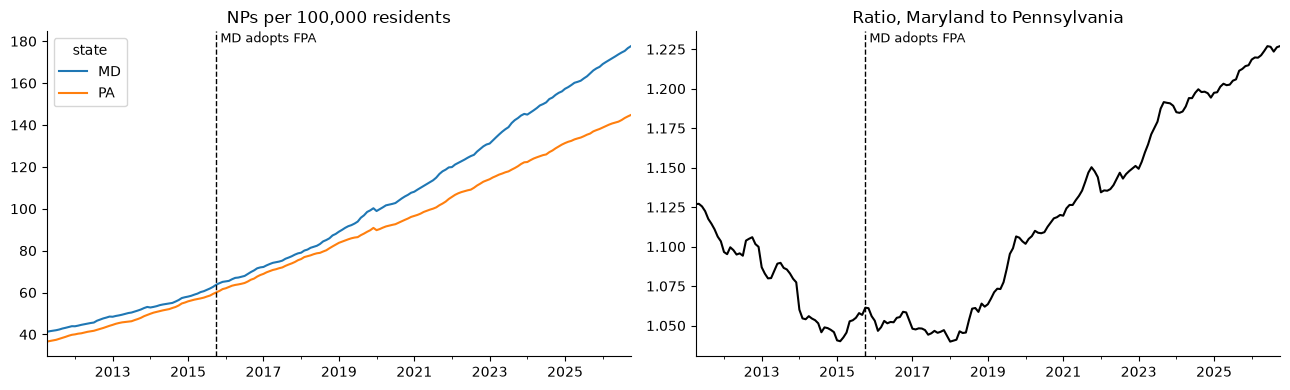

state,MD,PA,PA_to_MD,MD_to_PA,MD_growth_%,PA_growth_%
year,,,,,,
2012,"2,624","5,175",5,6,nan,nan
2013,"2,908","5,808",5,7,10.8,12.2
2014,"3,188","6,492",8,10,9.6,11.8
2015,"3,533","7,238",19,11,10.8,11.5
2016,"3,986","8,090",10,13,12.8,11.8
2017,"4,438","8,986",10,20,11.3,11.1
2018,"4,864","9,905",13,14,9.6,10.2
2019,"5,503","10,860",19,17,13.1,9.6
2020,"6,220","11,824",15,12,13.0,8.9


In [5]:
md_pa = panel[panel.state.isin(["MD", "PA"])].pivot(index="month", columns="state", values="nps_per_100k")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
md_pa.plot(ax=axes[0]); axes[0].axvline(pd.Period("2015-10", "M").ordinal, color="k", ls="--", lw=1)
axes[0].set_title("NPs per 100,000 residents"); axes[0].set_xlabel("")
(md_pa.MD / md_pa.PA).plot(ax=axes[1], color="k"); axes[1].axvline(pd.Period("2015-10", "M").ordinal, color="k", ls="--", lw=1)
axes[1].set_title("Ratio, Maryland to Pennsylvania"); axes[1].set_xlabel("")
for ax in axes: ax.text(pd.Period("2015-10", "M").ordinal, ax.get_ylim()[1], " MD adopts FPA", va="top", fontsize=9)
plt.tight_layout(); plt.show()

march = panel[(panel.state.isin(["MD", "PA"])) & (panel.month.dt.month == 3)].pivot(index="year", columns="state", values="nps")
mv = ev[(ev.event == "move") & (ev.month.dt.month.notna())]
march["PA_to_MD"] = mv[(mv.from_state == "PA") & (mv.state == "MD")].groupby(mv.date.dt.year).size()
march["MD_to_PA"] = mv[(mv.from_state == "MD") & (mv.state == "PA")].groupby(mv.date.dt.year).size()
march["MD_growth_%"] = march.MD.pct_change() * 100; march["PA_growth_%"] = march.PA.pct_change() * 100
march.loc[2012:2026].style.format({"MD": "{:,.0f}", "PA": "{:,.0f}", "PA_to_MD": "{:,.0f}", "MD_to_PA": "{:,.0f}", "MD_growth_%": "{:.1f}", "PA_growth_%": "{:.1f}"})

Three things the published comparison could not say:

1. **Pre-trend.** From 2012 to 2016 the two states grew at the same pace (Maryland 52%, Pennsylvania 56%), and from 2016 to 2021 Maryland pulled ahead (71% against 57%). But the ratio panel is more careful than the growth rates: Maryland's relative density was *falling* from 2011 to 2014, flat from 2014 to 2018, and rising only from 2018. The divergence starts about two and a half years after adoption, which is consistent with Maryland's time-in-practice rule (18 months of collaboration before independence) and also with something else happening in 2018. A snapshot comparison from 2016 on cannot tell those apart; the monthly series at least shows when the break is.
2. **Mobility is not the channel.** NPs moving from Pennsylvania to Maryland number ten to twenty a year, and about as many go the other way. The gap is far larger than the net flow.
3. **The gap keeps widening** through 2026, five years past their sample.

The border-county version of the same comparison, using the ZIP to county crosswalk and the Census county adjacency file, is in section 7.

## 4. All adoptions at once: descriptive event studies

For each state that adopted FPA inside the monthly window, NP density indexed to 100 in the adoption month, against the same index for the states that never adopted. Each panel is one cohort; the dashed line is adoption.

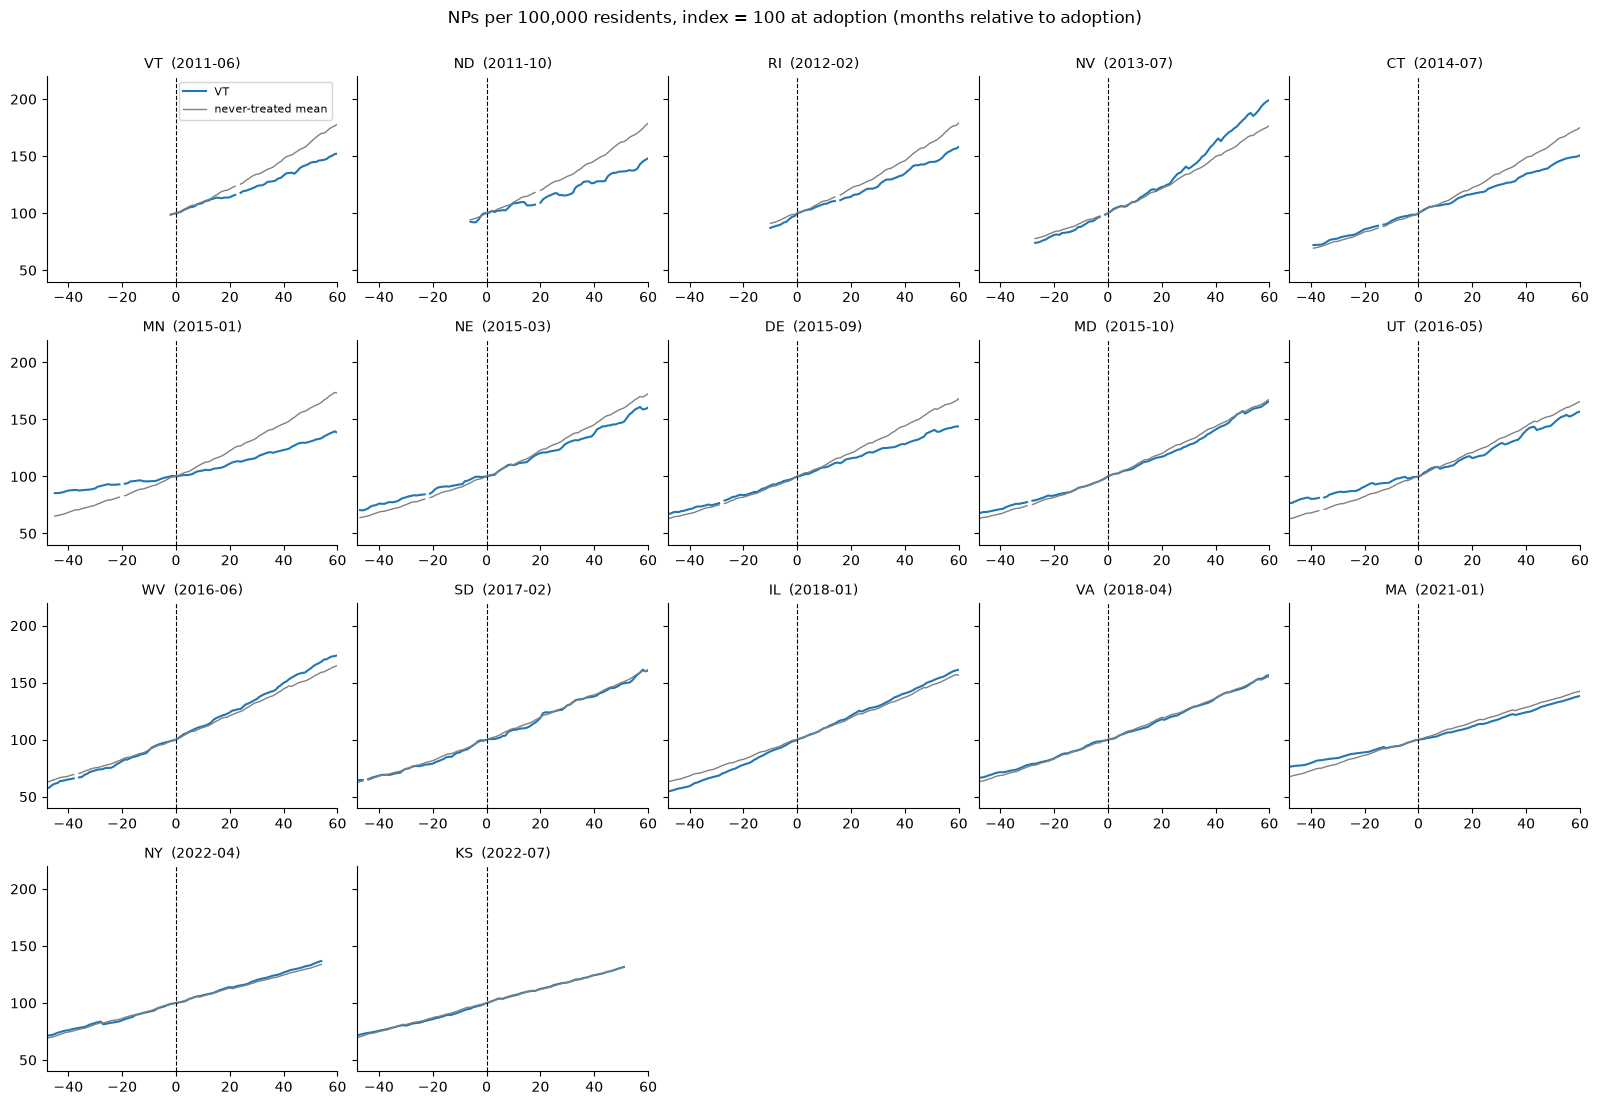

In [6]:
never = panel[panel.coding == "never"].groupby("month").nps_per_100k.mean()
cohorts = window[~window.partial]
fig, axes = plt.subplots(4, 5, figsize=(16, 11), sharey=True)
for ax, (_, r) in zip(axes.flat, cohorts.iterrows()):
    g = pd.Period(r.fpa_effective, "M")
    s = panel[panel.state == r.state].set_index("month").nps_per_100k
    base = s.get(g, np.nan)
    if np.isnan(base):
        ax.set_visible(False); continue
    rel = (s / base * 100); nrel = never / never[g] * 100
    k = range(-48, 61)
    ax.plot(k, [rel.get(g + i, np.nan) for i in k], label=r.state)
    ax.plot(k, [nrel.get(g + i, np.nan) for i in k], color="grey", lw=1, label="never-treated mean")
    ax.axvline(0, color="k", ls="--", lw=0.8); ax.set_title(f"{r.state}  ({g})", fontsize=10)
    ax.set_xlim(-48, 60); ax.set_ylim(40, 220)
for ax in axes.flat[len(cohorts):]: ax.set_visible(False)
axes[0, 0].legend(fontsize=8); fig.suptitle("NPs per 100,000 residents, index = 100 at adoption (months relative to adoption)", y=1.0)
plt.tight_layout(); plt.show()

Before adoption most cohorts track the never-treated mean (Minnesota and Illinois are the exceptions, with slower and faster pre-trends). After adoption more cohorts fall below the never-treated mean than above it: Vermont, North Dakota, Rhode Island, Connecticut, Minnesota, Nebraska, Delaware, Utah and Massachusetts grow more slowly than the states that never adopted, Nevada and West Virginia faster, and Maryland, South Dakota, Illinois, Virginia, New York and Kansas stay on the line. This is the picture the regressions below summarize. It is worth seeing raw first, because the never-treated group is dominated by fast-growing Sun Belt states, and "slower than Texas and Florida" is not the same as "slower than it would have been".

## 5. Staggered difference-in-differences

Treatment is staggered, so we use estimators that do not weight already-treated states as controls: Callaway and Sant'Anna's group-time ATT (the `differences` package, never-treated controls, quarterly to keep the number of group-time cells manageable) and Gardner's two-stage DID2S (`pyfixest`, monthly) for the dynamic plot. States with FPA before 1998, states that adopted before April 2011 and Florida (primary care only) are dropped. Standard errors are clustered by state.

Outcomes, all at the state-month level:

| Outcome | Definition |
|---|---|
| `log_nps_per_100k` | log NPs per 100,000 residents |
| `entry_rate` | new NPs (first appearance, or taxonomy switch into NP) per 1,000 NPs in the state, per quarter |
| `move_rate`, `move_out_rate` | NPs moving into / out of the state per 1,000 NPs, per quarter |
| `sp_share` | share of the state's NPs flagged sole proprietor |

In [7]:
est = panel[(panel.coding == "never") | ((panel.coding == "statute") & (panel.fpa_effective >= "2011-04-01") & ~panel.partial)].copy()
est["sid"] = est.state.astype("category").cat.codes
est["q"] = est.month.dt.asfreq("Q")
Q0 = pd.Period("2011Q2", "Q")
quarterly = (est.groupby(["state", "sid", "q"])
             .agg(log_nps_per_100k=("log_nps_per_100k", "last"), entry=("entry", "sum"), move=("move", "sum"),
                  move_out=("move_out", "sum"), nps=("nps", "mean"), sp_share=("sp_share", "last"), g=("g", "first"))
             .reset_index())
quarterly["t"] = (quarterly.q - Q0).apply(lambda x: x.n)
quarterly["gq"] = quarterly.g.apply(lambda x: (x.asfreq("Q") - Q0).n if pd.notna(x) else np.nan)
for c in ("entry", "move", "move_out"):
    quarterly[f"{c}_rate"] = quarterly[c] / quarterly.nps * 1000
outcomes = {"log_nps_per_100k": "log NPs per 100k", "entry_rate": "entries per 1,000 NPs per quarter",
            "move_rate": "in-moves per 1,000 NPs per quarter", "move_out_rate": "out-moves per 1,000 NPs per quarter", "sp_share": "sole-proprietor share"}
pre = quarterly[quarterly.gq.notna() & (quarterly.t < quarterly.gq)]
print(f"{est.state.nunique()} states: {est[est.coding == 'statute'].state.nunique()} treated cohorts, {est[est.coding == 'never'].state.nunique()} never treated")

results, dynamics = [], {}
for y, label in outcomes.items():
    att = ATTgt(data=quarterly.set_index(["sid", "t"]), cohort_column="gq")
    att.fit(formula=y, control_group="never_treated", progress_bar=False)
    s = att.aggregate("simple")
    results.append({"outcome": label, "ATT": s.iloc[0, 0], "se": s.iloc[0, 1], "pre-adoption mean, treated states": pre[y].mean()})
    dynamics[y] = att.aggregate("event")
pd.DataFrame(results).set_index("outcome")

36 states: 17 treated cohorts, 19 never treated


,ATT,se,"pre-adoption mean, treated states"
outcome,,,
log NPs per 100k,-0.052,0.033,4.121
"entries per 1,000 NPs per quarter",-0.605,4.461,31.962
"in-moves per 1,000 NPs per quarter",-0.540,0.883,5.374
"out-moves per 1,000 NPs per quarter",0.600,0.607,6.359
sole-proprietor share,0.004,0.006,0.141


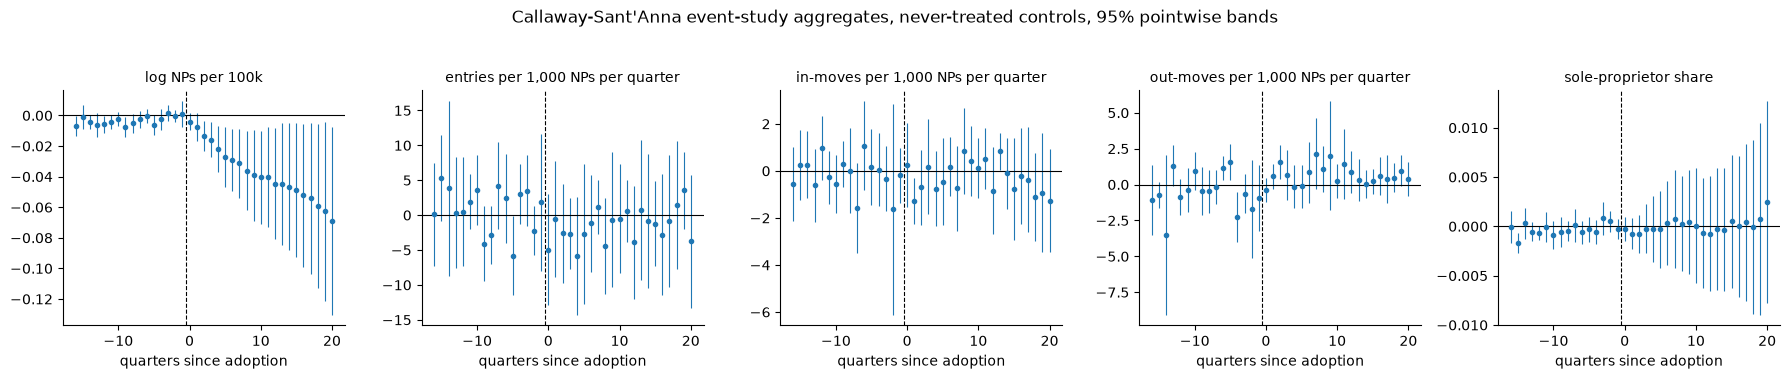

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, (y, label) in zip(axes, outcomes.items()):
    d = dynamics[y]; k = d.index.get_level_values(-1) if isinstance(d.index, pd.MultiIndex) else d.index
    k = np.asarray(k, dtype=float); keep = (k >= -16) & (k <= 20)
    ax.errorbar(k[keep], d.iloc[:, 0].values[keep], yerr=1.96 * d.iloc[:, 1].values[keep], fmt="o", ms=3, lw=0.8)
    ax.axhline(0, color="k", lw=0.8); ax.axvline(-0.5, color="k", ls="--", lw=0.8)
    ax.set_title(label, fontsize=10); ax.set_xlabel("quarters since adoption")
fig.suptitle("Callaway-Sant'Anna event-study aggregates, never-treated controls, 95% pointwise bands", y=1.04)
plt.tight_layout(); plt.show()

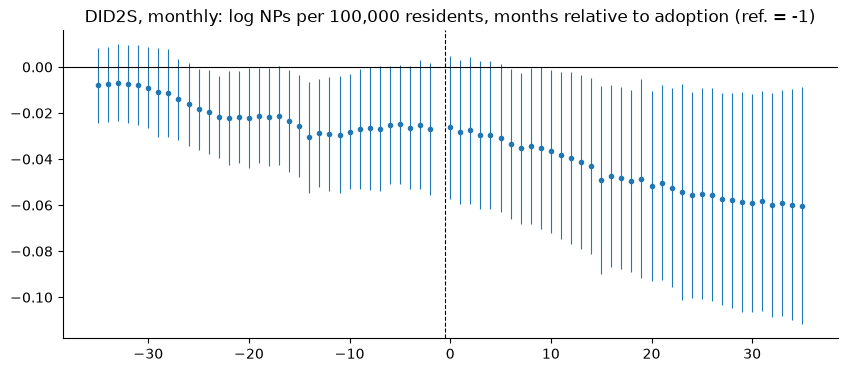

In [9]:
# Gardner DID2S on the monthly panel, dynamic effects on log NPs per 100k, binned at +-36 months
est["treat"] = (est.g_t.notna() & (est.t >= est.g_t)).astype(int)
est["rel"] = np.where(est.g_t.notna(), est.t - est.g_t, -1000.0)
est["rel_b"] = np.where(est.g_t.notna(), est.rel.clip(-36, 36), -1000.0)
fit = pf.did2s(est, yname="log_nps_per_100k", first_stage="~ 0 | sid + t", second_stage="~ i(rel_b, ref=-1)", treatment="treat", cluster="sid")
tidy = fit.tidy()
tidy["k"] = tidy.index.str.extract(r"::(-?[\d.]+)")[0].astype(float).values
tidy = tidy[(tidy.k > -1000) & (tidy.k.abs() < 36)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(tidy.k, tidy.Estimate, yerr=1.96 * tidy["Std. Error"], fmt="o", ms=3, lw=0.8)
ax.axhline(0, color="k", lw=0.8); ax.axvline(-0.5, color="k", ls="--", lw=0.8)
ax.set_title("DID2S, monthly: log NPs per 100,000 residents, months relative to adoption (ref. = -1)"); plt.show()

### Reading the estimates

* **Stock.** The average effect on NPs per capita is *negative*: about 5% fewer NPs per resident than the never-treated comparison implies (ATT -0.05 log points, standard error 0.03), with the Callaway-Sant'Anna dynamics flat before adoption and drifting to about -7% by five years after. The monthly two-stage estimator tells a less tidy story: relative to the month before adoption, the treated-minus-control gap was *rising* through the three pre-adoption years and falls afterwards, a hump that could be anticipation, mean reversion, or the choice of reference month. Either way, the comparison group matters: the never-treated states are heavy with Texas, Florida, Georgia and the Carolinas, whose NP counts grow fast for reasons that have nothing to do with scope of practice. The next cell swaps in not-yet-treated controls and the AANP classification; a paper would add region-by-time effects and population weights.
* **Entry and moves.** No detectable change in the rate at which new NPs appear, or in moves in or out, and the confidence bands are wide relative to the pre-adoption means. Across seventeen adoptions, the in-migration margin that the border literature worries about is flat.
* **Independence.** The sole-proprietor share does not move on average, which is the surprising one given the survey and job-posting results on self-employment. Two caveats: CMS's flag is self-reported and only means "unincorporated individual", and eleven FPA states impose a time-in-practice period of one to three years before an NP can drop the practice agreement, which would push any effect past the window shown here.

None of this contradicts Maryland. It says Maryland is not the average adoption, and that the average adoption did not add NPs.

In [10]:
# sensitivity: not-yet-treated controls, and the AANP classification
rows = []
for name, data, ctrl in [("never treated, M&M dates", quarterly, "never_treated"), ("not yet treated, M&M dates", quarterly, "not_yet_treated")]:
    att = ATTgt(data=data.set_index(["sid", "t"]), cohort_column="gq"); att.fit(formula="log_nps_per_100k", control_group=ctrl, progress_bar=False)
    s = att.aggregate("simple"); rows.append({"specification": name, "ATT log NPs per 100k": s.iloc[0, 0], "se": s.iloc[0, 1]})
# AANP: treated only if AANP also calls the state full practice; IL, VA, WV become never-treated
aanp = quarterly.merge(fpa[["state", "aanp_full_practice"]], on="state")
aanp.loc[~aanp.aanp_full_practice, "gq"] = np.nan
att = ATTgt(data=aanp.set_index(["sid", "t"]), cohort_column="gq"); att.fit(formula="log_nps_per_100k", control_group="never_treated", progress_bar=False)
s = att.aggregate("simple"); rows.append({"specification": "never treated, AANP classification", "ATT log NPs per 100k": s.iloc[0, 0], "se": s.iloc[0, 1]})
pd.DataFrame(rows).set_index("specification")

,ATT log NPs per 100k,se
specification,,
"never treated, M&M dates",-0.052,0.033
"not yet treated, M&M dates",-0.045,0.033
"never treated, AANP classification",-0.072,0.038


## 6. Who moves into an adopting state, and do they go independent?

The panel identifies each mover, so we can ask whether the NPs who arrive in a state after it adopts FPA look different from those who arrive elsewhere: where they came from, and whether they set up as sole proprietors within a year.

In [11]:
mv = ev[ev.event == "move"].merge(fpa[["state", "fpa_effective", "coding"]], on="state")
mv["months_since"] = (mv.date.dt.to_period("M") - mv.fpa_effective.dt.to_period("M")).apply(lambda x: x.n if pd.notna(x) else np.nan)
mv["group"] = np.select([(mv.coding == "statute") & mv.months_since.between(0, 24), (mv.coding == "never")],
                        ["into FPA state, first 2 years", "into never-FPA state"], "other")
sp = ev[ev.event == "became_sole_proprietor"][["npi", "date"]].rename(columns={"date": "sp_date"})
mv = mv.merge(sp, on="npi", how="left")
mv["sole_prop_within_year"] = (mv.sp_date >= mv.date) & (mv.sp_date <= mv.date + pd.DateOffset(years=1))
origin_fpa = fpa.set_index("state").coding.reindex(mv.from_state).values
mv["from_fpa_state"] = np.isin(origin_fpa, ["always", "statute"])
mv[mv.group != "other"].groupby("group").agg(moves=("npi", "size"), from_an_FPA_state=("from_fpa_state", "mean"),
                                             became_sole_proprietor_within_year=("sole_prop_within_year", "mean")).style.format({"from_an_FPA_state": "{:.1%}", "became_sole_proprietor_within_year": "{:.1%}"})

,moves,from_an_FPA_state,became_sole_proprietor_within_year
group,,,
"into FPA state, first 2 years",3585,51.4%,1.4%
into never-FPA state,39551,48.3%,1.3%


Movers into a state in its first two years of FPA look like movers anywhere else: about half come from a state that already had FPA, and between one and two percent set up as sole proprietors within a year. Nothing in the composition of movers suggests the law is pulling in NPs who want to practice independently.

## 7. Border counties for every adoption

Bae et al. compare the counties on each side of the Maryland-Pennsylvania line. With a ZIP to county crosswalk the same comparison can be made for every treated state against every untreated neighbour: NP count in border counties of the adopting state relative to the adjacent counties across the line, indexed to the adoption month.

98.4% of NP versions map to a county


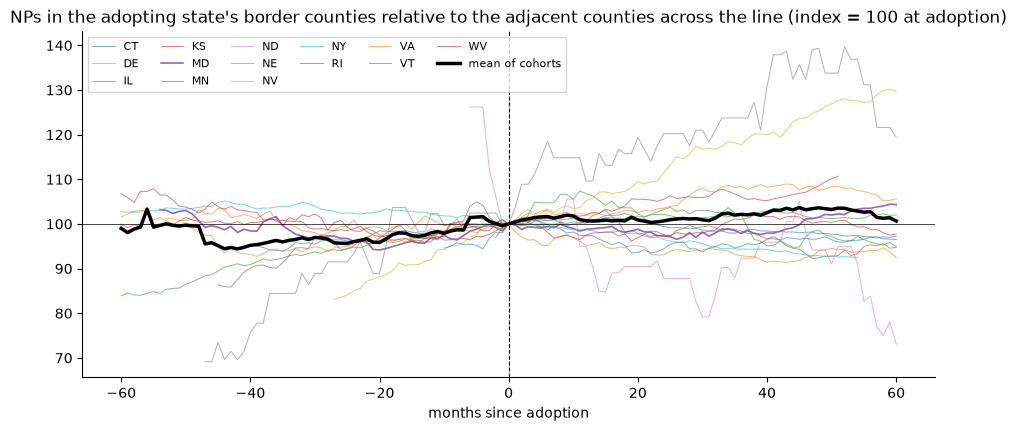

In [12]:
zc = pd.read_csv(nb.DATA / "zcta_county.csv", dtype=str)
pairs = pd.read_csv(nb.DATA / "state_border_county_pairs.csv", dtype=str)
fips_state = {"01":"AL","02":"AK","04":"AZ","05":"AR","06":"CA","08":"CO","09":"CT","10":"DE","11":"DC","12":"FL","13":"GA","15":"HI","16":"ID","17":"IL","18":"IN","19":"IA","20":"KS","21":"KY","22":"LA","23":"ME","24":"MD","25":"MA","26":"MI","27":"MN","28":"MS","29":"MO","30":"MT","31":"NE","32":"NV","33":"NH","34":"NJ","35":"NM","36":"NY","37":"NC","38":"ND","39":"OH","40":"OK","41":"OR","42":"PA","44":"RI","45":"SC","46":"SD","47":"TN","48":"TX","49":"UT","50":"VT","51":"VA","53":"WA","54":"WV","55":"WI","56":"WY"}
state_fips = {v: k for k, v in fips_state.items()}
v = versions[versions.is_np].copy()
v["county"] = v.practice_postal_code.str[:5].map(dict(zip(zc.zcta, zc.county_fips)))
print(f"{v.county.notna().mean():.1%} of NP versions map to a county")
start = v.effective_date.values; end = v.end_date.fillna(pd.Timestamp("2999-12-31")).values
untreated_by = lambda m: set(fpa[(fpa.coding == "never") | (fpa.fpa_effective.dt.to_period("M") > m + 60)].state)  # untreated through the window
rows = []
for _, r in cohorts.iterrows():
    g = pd.Period(r.fpa_effective, "M"); sf = state_fips[r.state]
    nbrs = pairs[(pairs.county_fips.str[:2] == sf) & pairs.neighbor_fips.str[:2].map(fips_state).isin(untreated_by(g))]
    own, across = set(nbrs.county_fips), set(nbrs.neighbor_fips)
    if not own: continue
    for d in dates:
        m = pd.Period(d, "M"); k = (m - g).n
        if abs(k) > 60: continue
        d64 = pd.Timestamp(d).to_datetime64(); live = v[(start <= d64) & (end > d64)]
        rows.append({"state": r.state, "k": k, "own": live.county.isin(own).sum(), "across": live.county.isin(across).sum()})
border = pd.DataFrame(rows)
base = border[border.k == 0].set_index("state")
border = border.merge(base[["own", "across"]].rename(columns={"own": "own0", "across": "across0"}), on="state")
border["ratio_index"] = (border.own / border.across) / (border.own0 / border.across0) * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
for st, d in border.groupby("state"):
    ax.plot(d.k, d.ratio_index, lw=1.2 if st == "MD" else 0.7, label=st, alpha=1 if st == "MD" else 0.6)
mean = border.groupby("k").ratio_index.mean(); ax.plot(mean.index, mean.values, color="k", lw=2.5, label="mean of cohorts")
ax.axvline(0, color="k", ls="--", lw=0.8); ax.axhline(100, color="k", lw=0.5)
ax.set_title("NPs in the adopting state's border counties relative to the adjacent counties across the line (index = 100 at adoption)")
ax.set_xlabel("months since adoption"); ax.legend(ncol=6, fontsize=8); plt.show()

The cohort mean stays within a few points of 100 for five years on either side of adoption. Maryland's border counties gain about five percent on Pennsylvania's within five years, which matches the state-level ratio in section 3 (the larger divergence comes later). The average adopting state does not gain NPs at its border relative to its untreated neighbours, which is consistent with the state-level estimates. Individual cohorts swing by 20 or 30 points because some border strips hold only a few hundred NPs.

## 8. What to be careful about

* **Practice address is one address.** NPPES holds a primary practice location (and, since July 2018, secondary locations in the `practice_location` table). NPs who work in several states appear once, where they put their primary address.
* **Sole proprietor is a CMS flag**, self-reported at enumeration or update, meaning an unincorporated individual. An NP who owns a practice through an LLC is not a sole proprietor; the 34,000 *organization* NPIs with an NP primary taxonomy would be a second place to look for NP-owned practices.
* **Time-in-practice rules.** Eleven FPA states require one to three years of supervised practice first, so the effective date of the law is not the date most NPs could use it.
* **Classification.** The McMichael and Markowitz and AANP codings disagree on four states; the sensitivity table shows the estimate is not driven by that choice.
* **Design.** Staggered adoption with a never-treated group that grows faster than the treated states before treatment. The pre-trend is visible and small; a paper would control for region-by-time or compare to not-yet-treated states, both of which this notebook shows how to do.
* **The panel is monthly from April 2011**, so the adoptions in Arizona, Hawaii, Colorado, Idaho and Washington cannot be used, and the Maryland 2010 attestation rule (which McMichael and Markowitz treat as the first FPA step) falls in the sparse years.

## 9. Where a researcher would go next

* Link the NPIs to Medicare or all-payer claims to see utilization, billing under the NP's own NPI, and patient panels, by month relative to adoption.
* Use `provider_taxonomy.license_state` across slots to measure multi-state licensure, and `practice_location` to count NPs practicing across a border without moving.
* Use the organization NPIs with NP taxonomies to date the opening of NP-owned practices.
* The same panel build (`nppes_nb.np_versions`, `np_events`, `np_stock_by_state_month`) works for any taxonomy family: swap `363L` for physician assistants (`363A`), certified registered nurse anesthetists (`367500000X`) or pharmacists (`1835`) and re-run against their scope-of-practice laws.